# Análise exploratória

In [1]:
# Bibliotecas
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Raiz do projeto ao path
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.database import get_engine

# Configurações globais de layout
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

engine = get_engine()
df = pd.read_sql("SELECT * FROM stg_bank_marketing", con=engine)
engine.dispose()

In [2]:
# Exibir as primeiras 5 linhas
df.head()

,age,job,marital,education,default_credit,balance,housing,loan,contact,day,month,campaign,pdays,previous_contact,previous,poutcome,target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,NaN,0,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,NaN,0,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,NaN,0,0,unknown,0


1. Dimensão e tipos dos dados.

In [3]:
print("Dimensão do Dataframe:", df.shape)

Dimensão do Dataframe: (45211, 17)


In [4]:
df.dtypes

age                   int64
job                     str
marital                 str
education               str
default_credit          str
balance               int64
housing                 str
loan                    str
contact                 str
day                   int64
month                   str
campaign              int64
pdays               float64
previous_contact      int64
previous              int64
poutcome                str
target                int64
dtype: object

2. Valores ausentes e categorias unknown.

In [5]:
print(df.isna().sum().sort_values(ascending=False).head(10))

pdays             36954
age                   0
job                   0
education             0
marital               0
balance               0
housing               0
loan                  0
default_credit        0
contact               0
dtype: int64


In [6]:
df.describe()

,age,balance,day,campaign,pdays,previous_contact,previous,target
count,45211.000000,45211.000000,45211.000000,45211.000000,8257.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,2.763841,224.577692,0.182633,0.580323,0.116985
std,10.618762,3044.765829,8.322476,3.098021,115.344035,0.386369,2.303441,0.321406
min,18.000000,-8019.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,33.000000,72.000000,8.000000,1.000000,133.000000,0.000000,0.000000,0.000000
50%,39.000000,448.000000,16.000000,2.000000,194.000000,0.000000,0.000000,0.000000
75%,48.000000,1428.000000,21.000000,3.000000,327.000000,0.000000,0.000000,0.000000
max,95.000000,102127.000000,31.000000,63.000000,871.000000,1.000000,275.000000,1.000000


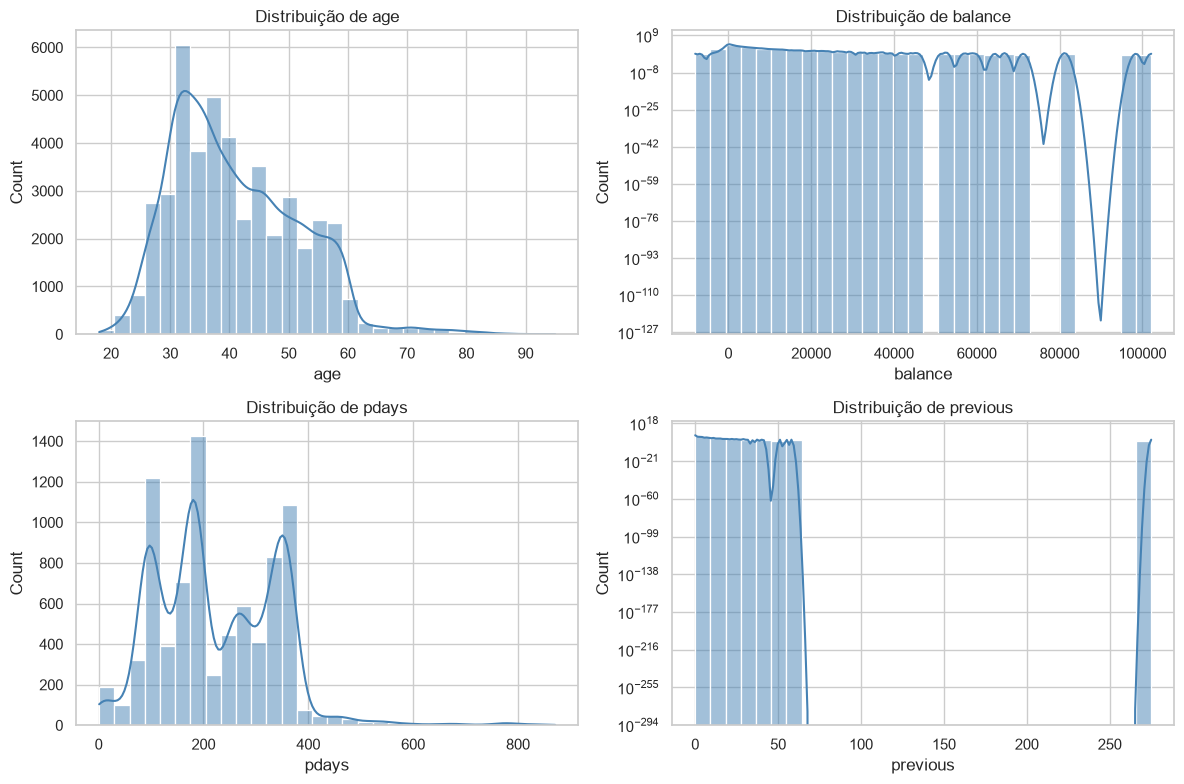

In [7]:
# Histograma para variáveis numéricas
colunas_continuas = ["age", "balance", "pdays", "previous"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(colunas_continuas):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color="steelblue", bins=30)
    axes[i].set_title(f"Distribuição de {col}")
    if col in ["balance", "previous"]:
        axes[i].set_yscale("log")  # Escala logarítmica para variáveis com cauda longa

plt.tight_layout()
plt.show()


3. Distribuição de target e taxa geral de conversão.

In [8]:
print("\nDistribuição do target:")
df["target"].value_counts(normalize=True).round(3)


Distribuição do target:


target
0    0.883
1    0.117
Name: proportion, dtype: float64

4. Taxa de conversão por ocupação, escolaridade, empréstimo habitacional e resultado de campanha anterior.

               count      mean
job                           
student          938  0.286780
retired         2264  0.227915
unemployed      1303  0.155027
management      9458  0.137556
admin.          5171  0.122027
self-employed   1579  0.118429
unknown          288  0.118056
technician      7597  0.110570
services        4154  0.088830
housemaid       1240  0.087903
entrepreneur    1487  0.082717
blue-collar     9732  0.072750


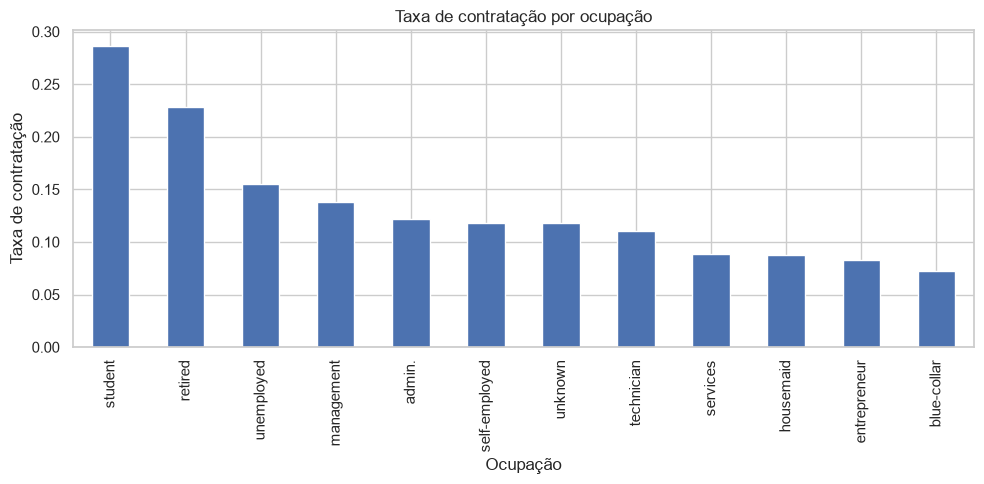

In [9]:
conversion_by_job = (
    df.groupby("job", dropna=False)["target"]
      .agg(["count", "mean"])
      .sort_values("mean", ascending=False)
)

print(conversion_by_job)

conversion_by_job["mean"].plot(kind="bar")
plt.title("Taxa de contratação por ocupação")
plt.ylabel("Taxa de contratação")
plt.xlabel("Ocupação")
plt.tight_layout()
plt.show()

5. Distribuição de idade e saldo.

C:\Users\yumi_\AppData\Local\Temp\ipykernel_17404\2950271601.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target', y='balance', ax=axes[1], palette='Set2')


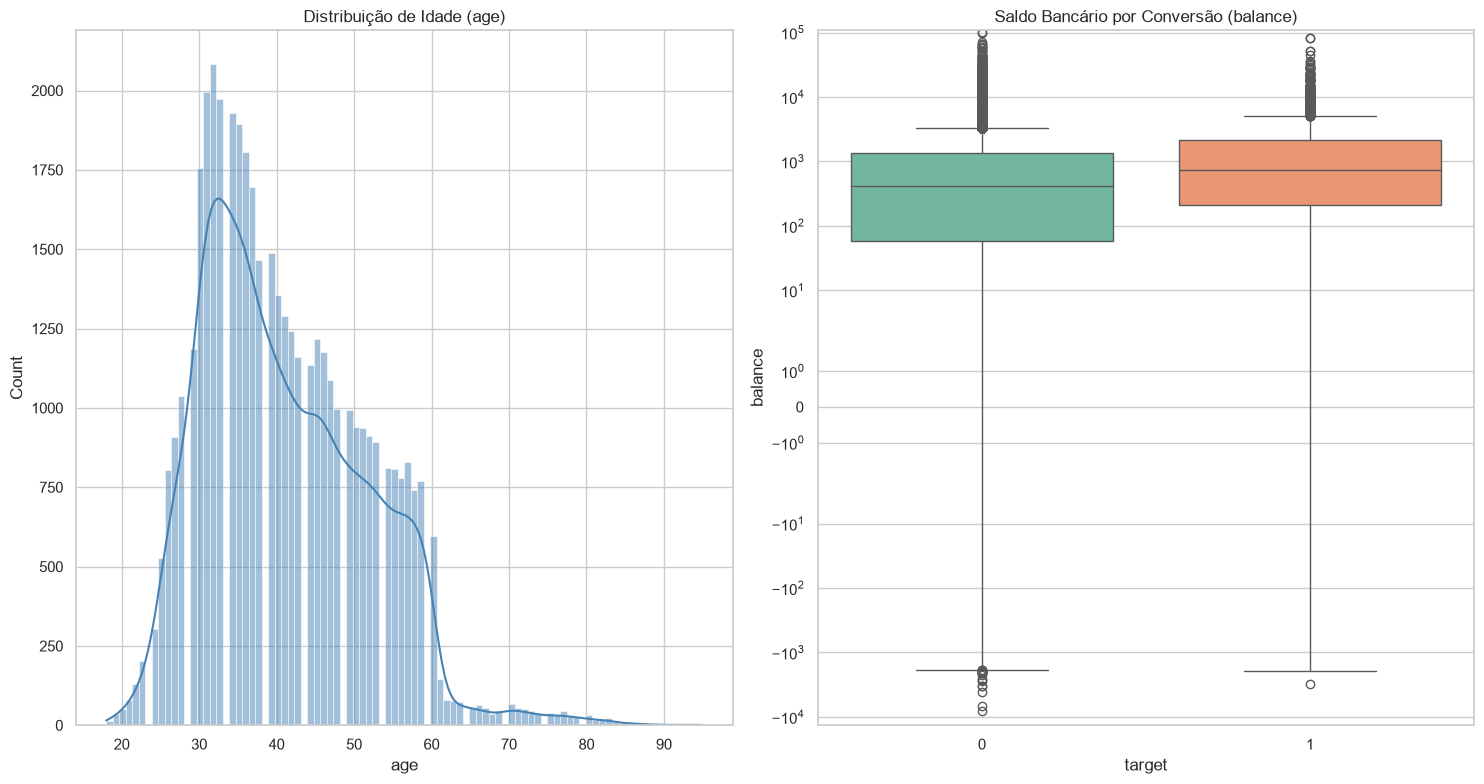

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# Idade
sns.histplot(data=df, x='age', kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Distribuição de Idade (age)")

# Saldo bancário (usando escala logarítmica ou limite para lidar com outliers)
sns.boxplot(data=df, x='target', y='balance', ax=axes[1], palette='Set2')
axes[1].set_title("Saldo Bancário por Conversão (balance)")
axes[1].set_yscale('symlog')  # Escala simétrica para aceitar saldos negativos

plt.tight_layout()
plt.show()

6. Discussão sobre desbalanceamento e limitações do conjunto de dados.

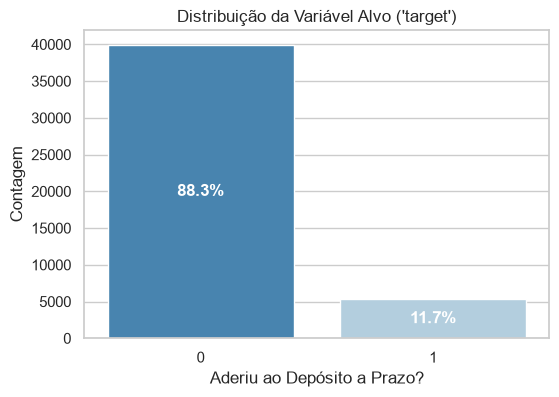

In [11]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='target', hue='target', palette='Blues_r', legend=False)

# Adiciona a porcentagem no topo de cada barra
total = len(df)
for p in ax.patches:
    pct = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(pct, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.title("Distribuição da Variável Alvo ('target')")
plt.xlabel("Aderiu ao Depósito a Prazo?")
plt.ylabel("Contagem")
plt.show()

C:\Users\yumi_\AppData\Local\Temp\ipykernel_17404\3602966070.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=resumo, x=coluna, y="taxa_pct", palette="Blues_r")


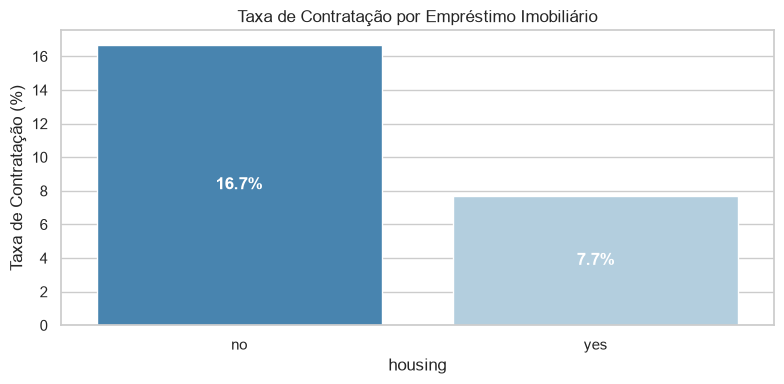

C:\Users\yumi_\AppData\Local\Temp\ipykernel_17404\3602966070.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=resumo, x=coluna, y="taxa_pct", palette="Blues_r")


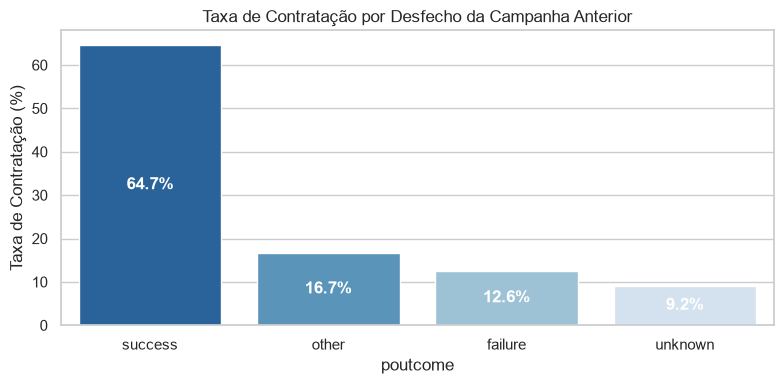

In [12]:
def plotar_taxa_aceite(dataframe, coluna, titulo):
    resumo = (
        dataframe.groupby(coluna, dropna=False)["target"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
        .reset_index()
    )
    resumo["taxa_pct"] = resumo["mean"] * 100

    plt.figure(figsize=(8, 4))
    ax = sns.barplot(data=resumo, x=coluna, y="taxa_pct", palette="Blues_r")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", 
                    (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                    ha="center", va="center", color="white", fontweight="bold")
    plt.title(titulo)
    plt.ylabel("Taxa de Contratação (%)")
    plt.xlabel(coluna)
    plt.tight_layout()
    plt.show()

plotar_taxa_aceite(df, "housing", "Taxa de Contratação por Empréstimo Imobiliário")
plotar_taxa_aceite(df, "poutcome", "Taxa de Contratação por Desfecho da Campanha Anterior")

### Matriz de Correlação

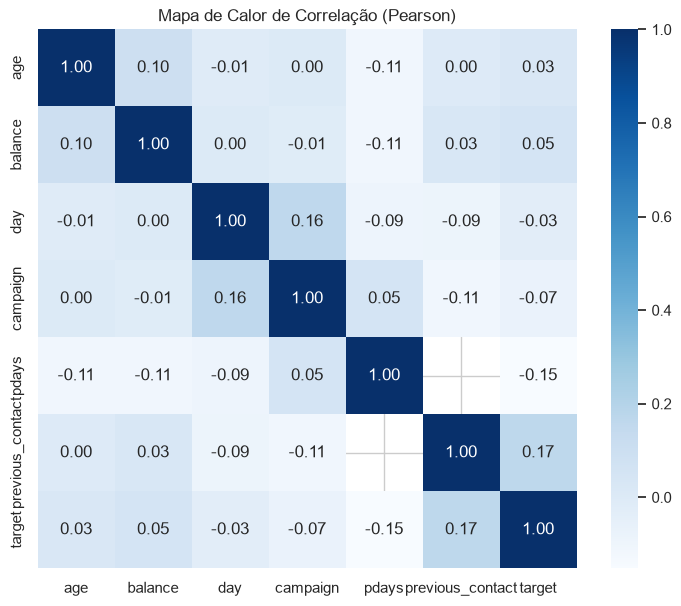

In [13]:
colunas_num = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous_contact', 'target']
colunas_cat = ['poutcome', 'target']

# Mapa de calor de correlação
df[colunas_num].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(df[colunas_num].corr(), annot=True, fmt=".2f", cmap='Blues', cbar=True, square=True)
plt.title("Mapa de Calor de Correlação (Pearson)")
plt.show()